# VitaSync Emergency Inventory Demo (Corrected)

## Problem statement in plain language
This notebook demonstrates **four separate toy problems**, all on synthetic or fictional data. They are **not** "one AI algorithm" and they do not feed each other in a real pipeline.

| # | Toy problem | Method | Output | What it is **not** |
|---|---|---|---|---|
| 1 | Estimate a daily aggregate synthetic demand target from 8 tabular features | `RandomForestRegressor` | One estimate per day, in the dataset's unspecified synthetic units | Not observed clinical demand, not component/blood-group specific, not camera detection |
| 2 | Find the least-travel-time route across a fictional site graph | NetworkX weighted shortest path (Dijkstra) | A sample route and a simulated ETA | Not a real map, vehicle dispatch, traffic prediction or inventory-and-route optimizer |
| 3 | Order staff-submitted *simulated* requests for review | `heapq` priority queue with a transparent weighted score | A review queue with the score's factor breakdown | Not ML, not clinically validated triage, not a bulk allocation optimizer |
| 4 | Pick a fictional replenishment quantity in a simplified inventory simulator | Stable-Baselines3 **PPO** in a toy Gymnasium environment | Daily order actions and toy simulation cost totals | Not evidence of a good or superior policy, not real-world performance |
| 5 | Choose a source site for each request | Greedy nearest-source heuristic with a temporary in-memory stock ledger | A recommendation with an explicit status | Not a MILP, not globally optimal, never splits a request across sources |

**This notebook does not:** perform clinical triage, detect blood bags with a camera, optimize real transfers, verify blood compatibility, or control traffic lights. It has no real-time backend, no camera/OCR model and no ResQtech connection.

**Other design limits.** There is one fictional component category. Locations, stock, urgency levels, deadlines and edge travel times are fabricated. The Kaggle donor dataset is not inventory or image data, and the demand data does not train camera recognition.

Every section ends with automatic checks that print `PASS`/`FAIL`, and the final proof JSON records them. Run **Runtime → Run all**.

## What is corrected relative to the submitted notebook
- **Late routes are now flagged.** Previously `SIM-101` was routed in a simulated 28 minutes against a 12-minute deadline and still reported plain `REVIEW_REQUIRED`. Recommendations now carry `arrival_feasible`, `deadline_slack_min` and a distinct `LATE_ROUTE_REVIEW` status, and a late route does not reserve stock.
- **Local fulfillment is separate from a transfer.** A source equal to the destination is reported as `LOCAL_FULFILLMENT_REVIEW_REQUIRED` with zero transport time, and other sites are considered only when local stock is insufficient.
- **Consistent RL scaling.** The test environment is normalised with the train-derived scale PPO was trained with (previously with test statistics).
- **Meaningful RL objective.** The cost function is rebalanced (the old PPO "won" by ordering the maximum amount every day) and PPO is compared with baselines over 3 seeds.
- **Validation split is used.** The validation split picks the Random Forest settings, and the test split is touched once.
- **Robust loading.** Data loading validates the archive, filename, columns, rows, dates and numeric types with readable errors.
- **Tests.** Added tests for route deadline status, local fulfillment, insufficient and duplicate stock, and artifact existence.
- **Restart-safe.** The notebook installs only missing packages and can be run twice in the same runtime.

*If a pip install ever triggers a binary-compatibility error such as `numpy.dtype size changed`, choose **Runtime → Restart session** and then **Run all**. Nothing else needs to change.*

In [1]:
# 1. Setup: core libraries (preinstalled in Colab)
import importlib, subprocess, sys, os, io, json, random, zipfile, hashlib, platform, warnings, heapq, copy
from pathlib import Path

def ensure(pip_name, module=None):
    # Import a package, pip-installing it first if it is missing.
    try:
        importlib.import_module(module or pip_name)
    except ImportError:
        print(f'Installing {pip_name} ...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])

for _pkg, _mod in [('numpy', None), ('pandas', None), ('scikit-learn', 'sklearn'),
                   ('networkx', None), ('matplotlib', None), ('joblib', None), ('requests', None)]:
    ensure(_pkg, _mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, networkx as nx, joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
random.seed(SEED); np.random.seed(SEED)
CHECKS = {}   # name -> bool, filled in by every section and written to the proof file

def check(name, condition, detail=''):
    CHECKS[name] = bool(condition)
    print(('PASS' if condition else 'FAIL'), '-', name, ('| ' + str(detail)) if detail else '')

print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
       'scikit_learn': sklearn.__version__, 'networkx': nx.__version__})

{'python': '3.12.3', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit_learn': '1.8.0', 'networkx': '3.6.1'}


## 2. Dataset audit and safe load

**Dataset notes (preserved).**
- **Demand dataset:** [Kaggle Blood Demand Dataset](https://www.kaggle.com/datasets/rishi2003das/blood-demand-dataset). It is a synthetic daily series (the earlier executed run saw 1,827 rows, 2020-01-01 to 2024-12-31) with target `PredictedBloodDemand`. Kaggle lists **GPL-3.0**, so review the license before redistributing the data or derived artifacts.
- **Donor dataset:** a 10,000-row synthetic donor directory with names, emails, phone numbers and passwords (Kaggle lists CC0). It is not inventory, image or demand data, so it is **never downloaded or used**, and identifiers or credentials must never become model inputs.
- **Loader order:** local CSV → public Kaggle download → Colab upload → clearly labelled *surrogate* (a schema-matched fake series used only to test the pipeline; its metrics say nothing about the real data). Set `ALLOW_SURROGATE = False` to require real data.

In [2]:
DEMAND_DATASET_PAGE = 'https://www.kaggle.com/datasets/rishi2003das/blood-demand-dataset'
DEMAND_DOWNLOAD = 'https://www.kaggle.com/api/v1/datasets/download/rishi2003das/blood-demand-dataset?datasetVersionNumber=1'
CSV_NAME = 'synthetic_blood_demand_data.csv'
ALLOW_SURROGATE = True   # set False to force real data (the notebook then stops if it cannot get it)

def make_surrogate_demand_data(seed=SEED):
    # Schema-matched FAKE daily series, used only when the real CSV cannot be obtained.
    rng = np.random.default_rng(seed)
    dates = pd.date_range('2020-01-01', '2024-12-31', freq='D')
    n = len(dates)
    t = np.arange(n)
    dow = dates.dayofweek.to_numpy(); month = dates.month.to_numpy()
    season = np.sin(2 * np.pi * (dates.dayofyear.to_numpy() - 80) / 365.25)
    population = 1_000_000 + 60 * t + rng.normal(0, 3000, n)
    events = rng.binomial(1, 0.08, n)
    temperature = 22 + 9 * season + rng.normal(0, 2.5, n)
    admissions = 180 + 12 * (dow < 5) + 25 * events + 6 * season + rng.normal(0, 10, n)
    donors = 140 + 15 * (dow < 5) - 10 * events + rng.normal(0, 12, n)
    true_demand = 120 + 0.55 * admissions + 30 * events + 0.00005 * population + 4 * season + rng.normal(0, 6, n)
    historical = 0.85 * true_demand + 35 + rng.normal(0, 25, n)
    return pd.DataFrame({'Date': dates, 'DayOfWeek': dow, 'Month': month, 'Population': population.round(),
                         'Events': events, 'HistoricalBloodUsage': historical.round(2),
                         'HospitalAdmissions': admissions.round(2), 'BloodDonorsAvailable': donors.round(2),
                         'Temperature': temperature.round(2),
                         'PredictedBloodDemand': (true_demand + rng.normal(0, 10, n)).round(2)})

def load_demand_data():
    local = Path(CSV_NAME)
    if local.exists():
        return pd.read_csv(local), f'local file {local}', 'real'
    try:
        import requests
        r = requests.get(DEMAND_DOWNLOAD, timeout=30, headers={'User-Agent': 'Mozilla/5.0'})
        r.raise_for_status()
        zf = zipfile.ZipFile(io.BytesIO(r.content))
        matches = [n for n in zf.namelist() if Path(n).name == CSV_NAME]
        if not matches:
            raise FileNotFoundError(f'{CSV_NAME} not in archive: {zf.namelist()}')
        return pd.read_csv(zf.open(matches[0])), f'Kaggle public download: {DEMAND_DATASET_PAGE}', 'real'
    except Exception as exc:
        print('Public download did not work:', repr(exc)[:200])
    try:
        from google.colab import files
        print(f'Please upload {CSV_NAME} (cancel the dialog to use the surrogate instead).')
        uploaded = files.upload()
        if CSV_NAME in uploaded:
            return pd.read_csv(io.BytesIO(uploaded[CSV_NAME])), 'manual upload in Colab', 'real'
        print(f'No file named exactly {CSV_NAME} was uploaded.')
    except Exception as exc:
        print('No Colab upload available:', repr(exc)[:120])
    if ALLOW_SURROGATE:
        return make_surrogate_demand_data(), 'SURROGATE (fake, schema-matched)', 'SURROGATE'
    raise RuntimeError(f'Could not obtain real data. Put {CSV_NAME} next to the notebook and rerun.')

df_raw, DATA_SOURCE, DATA_MODE = load_demand_data()
DATA_BANNER = f'[DATA MODE: {DATA_MODE}]'
print(DATA_BANNER, '| Source:', DATA_SOURCE)
if DATA_MODE != 'real':
    print('*** WARNING: metrics below come from FAKE surrogate data. They prove the code runs, not how the model does on real data. ***')
print('Dimensions:', df_raw.shape)
print('Columns:', list(df_raw.columns))

Public download did not work: HTTPError('403 Client Error: Forbidden for url: https://www.kaggle.com/api/v1/datasets/download/rishi2003das/blood-demand-dataset?datasetVersionNumber=1')
No Colab upload available: ModuleNotFoundError("No module named 'google.colab'")
[DATA MODE: SURROGATE] | Source: SURROGATE (fake, schema-matched)
*** WARNING: metrics below come from FAKE surrogate data. They prove the code runs, not how the model does on real data. ***
Dimensions: (1827, 10)
Columns: ['Date', 'DayOfWeek', 'Month', 'Population', 'Events', 'HistoricalBloodUsage', 'HospitalAdmissions', 'BloodDonorsAvailable', 'Temperature', 'PredictedBloodDemand']


In [3]:
# Validate the loaded frame with readable errors, then keep only usable rows.
EXPECTED_FEATURES = ['DayOfWeek', 'Month', 'Population', 'Events', 'HistoricalBloodUsage',
                     'HospitalAdmissions', 'BloodDonorsAvailable', 'Temperature']
col_lookup = {str(c).strip().casefold(): c for c in df_raw.columns}

def validate_demand_frame(frame):
    problems = []
    if len(frame) < 200: problems.append(f'only {len(frame)} rows (need at least 200)')
    tcol = col_lookup.get('predict(blooddemand)') or col_lookup.get('predictedblooddemand')
    dcol = col_lookup.get('date') or col_lookup.get('datetime')
    if tcol is None: problems.append('target column PredictedBloodDemand not found')
    if dcol is None: problems.append('Date/DateTime column not found')
    missing = [f for f in EXPECTED_FEATURES if f.casefold() not in col_lookup]
    if missing: problems.append(f'missing feature columns: {missing}')
    if not problems:
        if pd.to_datetime(frame[dcol], errors='coerce').notna().mean() < 0.95: problems.append('less than 95% of dates could be parsed')
        if pd.to_numeric(frame[tcol], errors='coerce').notna().mean() < 0.95: problems.append('less than 95% of target values are numeric')
        for f in EXPECTED_FEATURES:
            if pd.to_numeric(frame[col_lookup[f.casefold()]], errors='coerce').notna().mean() < 0.95:
                problems.append(f'feature {f} is less than 95% numeric')
    if problems:
        raise ValueError('The demand CSV failed validation:\n - ' + '\n - '.join(problems) +
                         f'\nColumns found: {list(frame.columns)}\nFix the file (or delete it so the notebook can re-download) and rerun this cell.')
    return tcol, dcol

target_col, date_col = validate_demand_frame(df_raw)

df = df_raw.copy()
df['_date'] = pd.to_datetime(df[date_col], errors='coerce')
df['_target'] = pd.to_numeric(df[target_col], errors='coerce')
df = df.dropna(subset=['_date', '_target']).sort_values('_date').reset_index(drop=True)
print(DATA_BANNER, 'Usable rows:', len(df), '| date range:', df['_date'].min().date(), 'to', df['_date'].max().date())
print('Target:', target_col, '| min/max:', round(float(df['_target'].min()), 2), '/', round(float(df['_target'].max()), 2))
print(df[[date_col, target_col]].head(5).to_string(index=False))
check('data_has_rows_and_dates', len(df) > 500 and df['_date'].is_monotonic_increasing, f'{len(df)} rows')
check('no_duplicate_dates', df['_date'].is_unique)
check('all_expected_features_present', all(f.casefold() in col_lookup for f in EXPECTED_FEATURES))

[DATA MODE: SURROGATE] Usable rows: 1827 | date range: 2020-01-01 to 2024-12-31
Target: PredictedBloodDemand | min/max: 225.31 / 347.56
      Date  PredictedBloodDemand
2020-01-01                278.55
2020-01-02                308.70
2020-01-03                281.84
2020-01-04                263.72
2020-01-05                254.25
PASS - data_has_rows_and_dates | 1827 rows
PASS - no_duplicate_dates 
PASS - all_expected_features_present 


## 3. RandomForestRegressor: synthetic demand regression

**Problem.** Estimate the dataset's `PredictedBloodDemand` number for a day from eight tabular columns: `DayOfWeek`, `Month`, `Population`, `Events`, `HistoricalBloodUsage`, `HospitalAdmissions`, `BloodDonorsAvailable`, `Temperature`.

**How the algorithm solves it.** A Random Forest is many decision trees, each trained on a random resample of the days. Each tree learns "if admissions are high and it is a weekday then the estimate is high"-style rules. The forest averages the trees' guesses, which is steadier than any single tree.

**Output.** One estimate per day in the dataset's **unspecified synthetic units**.

**What the numbers mean.** The target is synthetic and already named "predicted". MAE, RMSE and R² measure fit to that synthetic column **only**. They are not observed clinical demand, not component/blood-group specific demand, and not camera detection.

**Method.** The data is split in time order (70% train, 15% validation, 15% test) so the model never trains on the future. Six settings are compared on validation. The best is refit on train+validation and scored once on test, against two naive baselines (copy `HistoricalBloodUsage`, and predict the train mean).

In [4]:
feature_aliases = ['DayOfWeek', 'Month', 'Population', 'Events', 'HistoricalBloodUsage',
                   'HospitalAdmissions', 'BloodDonorsAvailable', 'Temperature']
feature_cols = [col_lookup[a.casefold()] for a in feature_aliases if a.casefold() in col_lookup]
if not feature_cols: raise ValueError('No expected numeric predictors found.')
history_col = col_lookup.get('historicalbloodusage')
if history_col is None: raise KeyError('HistoricalBloodUsage is required for the naive baseline.')
for c in feature_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=['_date', '_target'] + feature_cols).sort_values('_date').reset_index(drop=True)

n = len(df); train_end, valid_end = int(n * 0.70), int(n * 0.85)
train, valid, test = df.iloc[:train_end].copy(), df.iloc[train_end:valid_end].copy(), df.iloc[valid_end:].copy()
X_train, y_train = train[feature_cols], train['_target']
X_valid, y_valid = valid[feature_cols], valid['_target']
X_test, y_test = test[feature_cols], test['_target']
print(f'Rows: train={len(train)}, validation={len(valid)}, test={len(test)}')
print('Train', train['_date'].min().date(), '->', train['_date'].max().date(), '| Valid', valid['_date'].min().date(), '->',
      valid['_date'].max().date(), '| Test', test['_date'].min().date(), '->', test['_date'].max().date())
print('Features:', feature_cols)

check('split_is_chronological', train['_date'].max() < valid['_date'].min() and valid['_date'].max() < test['_date'].min())
check('split_covers_all_rows', len(train) + len(valid) + len(test) == n)
banned = ('email', 'password', 'phone', 'name', 'donor_id', 'donorid', 'donor_name')
check('no_identifier_features', not any(b in str(c).casefold() for c in feature_cols for b in banned) and
      all(str(c).casefold() != 'id' for c in feature_cols))

Rows: train=1278, validation=274, test=275
Train 2020-01-01 -> 2023-07-01 | Valid 2023-07-02 -> 2024-03-31 | Test 2024-04-01 -> 2024-12-31
Features: ['DayOfWeek', 'Month', 'Population', 'Events', 'HistoricalBloodUsage', 'HospitalAdmissions', 'BloodDonorsAvailable', 'Temperature']
PASS - split_is_chronological 
PASS - split_covers_all_rows 
PASS - no_identifier_features 


In [5]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def regression_metrics(y, p):
    return {'MAE': float(mean_absolute_error(y, p)), 'RMSE': rmse(y, p), 'R2': float(r2_score(y, p))}

def fit_rf(cfg, X, y):
    return RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1, **cfg).fit(X, y)

configs = [dict(min_samples_leaf=l, max_features=f) for l in (1, 3, 5) for f in (0.6, 0.9)]
val_table = []
for cfg in configs:
    m = fit_rf(cfg, X_train, y_train)
    val_table.append({**cfg, 'val_RMSE': rmse(y_valid, m.predict(X_valid))})
val_table = pd.DataFrame(val_table).sort_values('val_RMSE').reset_index(drop=True)
print('Validation search (lower is better):'); print(val_table.round(3).to_string(index=False))
best_cfg = {'min_samples_leaf': int(val_table.loc[0, 'min_samples_leaf']), 'max_features': float(val_table.loc[0, 'max_features'])}
print('Chosen config:', best_cfg)

valid_model = fit_rf(best_cfg, X_train, y_train)                       # train only, honest validation score
forecast_model = fit_rf(best_cfg, pd.concat([X_train, X_valid]), pd.concat([y_train, y_valid]))   # final model
valid_pred, test_pred = valid_model.predict(X_valid), forecast_model.predict(X_test)

median_fill = float(y_train.median())
base_valid = pd.to_numeric(valid[history_col], errors='coerce').fillna(median_fill).to_numpy()
base_test = pd.to_numeric(test[history_col], errors='coerce').fillna(median_fill).to_numpy()
mean_test = np.full(len(test), float(y_train.mean()))
metrics = {'validation_random_forest': regression_metrics(y_valid, valid_pred),
           'validation_naive_historical_usage': regression_metrics(y_valid, base_valid),
           'test_random_forest': regression_metrics(y_test, test_pred),
           'test_naive_historical_usage': regression_metrics(y_test, base_test),
           'test_train_mean': regression_metrics(y_test, mean_test)}
print(DATA_BANNER); print(json.dumps(metrics, indent=2))

importances = pd.Series(forecast_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print('\nFeature importance (share of the forest\'s splits):'); print(importances.round(3).to_string())
print('\nHeld-out examples:')
print(pd.DataFrame({'date': test['_date'].dt.date.to_numpy(), 'actual_synthetic_target': y_test.to_numpy(),
                    'model_prediction': test_pred, 'naive_historical_usage': base_test}).head(8).round(2).to_string(index=False))

check('metrics_are_finite', all(np.isfinite(v) for d in metrics.values() for v in d.values()))
check('rf_beats_naive_on_test_rmse', metrics['test_random_forest']['RMSE'] < metrics['test_naive_historical_usage']['RMSE'],
      f"RF {metrics['test_random_forest']['RMSE']:.2f} vs naive {metrics['test_naive_historical_usage']['RMSE']:.2f}")
check('rf_beats_train_mean_on_test_rmse', metrics['test_random_forest']['RMSE'] < metrics['test_train_mean']['RMSE'])

Validation search (lower is better):
 min_samples_leaf  max_features  val_RMSE
                5           0.6    11.986
                3           0.6    12.102
                5           0.9    12.130
                1           0.6    12.168
                3           0.9    12.258
                1           0.9    12.532
Chosen config: {'min_samples_leaf': 5, 'max_features': 0.6}
[DATA MODE: SURROGATE]
{
  "validation_random_forest": {
    "MAE": 9.631501235640398,
    "RMSE": 11.985616127850165,
    "R2": 0.550976380226767
  },
  "validation_naive_historical_usage": {
    "MAE": 21.797189781021896,
    "RMSE": 26.94370388786739,
    "R2": -1.269149199410593
  },
  "test_random_forest": {
    "MAE": 10.22091309148995,
    "RMSE": 12.97574159514788,
    "R2": 0.5071887194827867
  },
  "test_naive_historical_usage": {
    "MAE": 22.662509090909094,
    "RMSE": 27.73038864101652,
    "R2": -1.250754755445822
  },
  "test_train_mean": {
    "MAE": 14.115905676483145,
    "RMSE": 18

PASS - chart_saved 


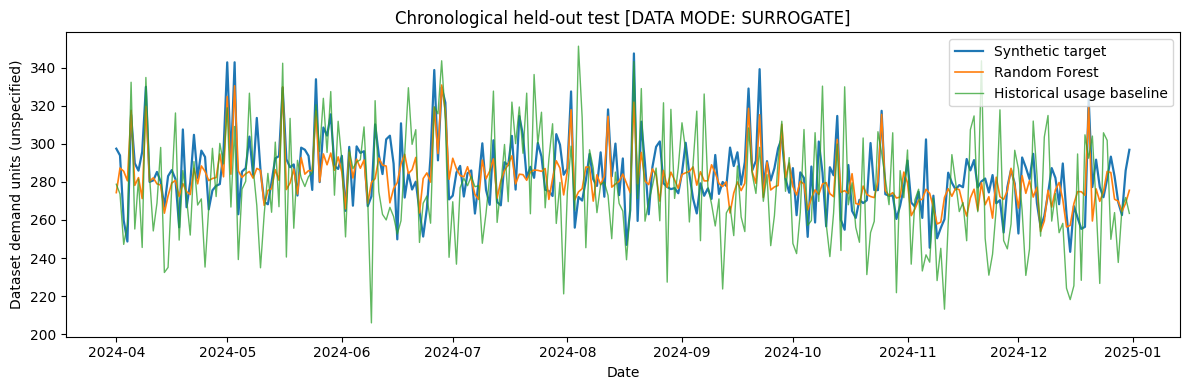

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(test['_date'], y_test, label='Synthetic target', linewidth=1.6)
plt.plot(test['_date'], test_pred, label='Random Forest', linewidth=1.2)
plt.plot(test['_date'], base_test, label='Historical usage baseline', alpha=.75, linewidth=1)
plt.title(f'Chronological held-out test {DATA_BANNER}')
plt.xlabel('Date'); plt.ylabel('Dataset demand units (unspecified)'); plt.legend(); plt.tight_layout()
plt.savefig('demand_forecast_test.png', dpi=140)
plt.show()
check('chart_saved', Path('demand_forecast_test.png').stat().st_size > 5000)

## 4. NetworkX weighted shortest path: toy route calculation

**Problem.** Given a source site and a destination, find the path whose **sum of fictional edge travel-time weights** is smallest.

**How it works.** Dijkstra's algorithm repeatedly expands the closest unfinished site and updates its neighbours' best-known times. Direct Depot-A→Site-C costs 31 min, while Depot-A→Site-B→Site-C costs 18 + 10 = 28 min, so the second wins.

**Output.** A sample route and a simulated ETA in minutes. **Not** a real map, vehicle dispatch, traffic prediction, or a joint inventory-and-route optimizer.

NetworkX's answers are cross-checked against a from-scratch Dijkstra for every pair of sites.

In [7]:
G = nx.Graph()
G.add_weighted_edges_from([('Depot-A', 'Site-B', 18), ('Depot-A', 'Site-C', 31), ('Site-B', 'Site-C', 10),
                           ('Site-B', 'Site-D', 27), ('Site-C', 'Site-D', 12)], weight='travel_time_min')
print('Nodes:', G.number_of_nodes(), '| edges:', G.number_of_edges(), '| connected:', nx.is_connected(G))
print('Shortest Depot-A -> Site-C:', nx.shortest_path(G, 'Depot-A', 'Site-C', weight='travel_time_min'),
      '|', nx.shortest_path_length(G, 'Depot-A', 'Site-C', weight='travel_time_min'), 'min')

def my_dijkstra(graph, src):
    # Independent implementation: always expand the closest unfinished site.
    dist = {src: 0}; heap = [(0, src)]
    while heap:
        d, u = heapq.heappop(heap)
        if d > dist.get(u, float('inf')): continue
        for v, attrs in graph[u].items():
            nd = d + attrs['travel_time_min']
            if nd < dist.get(v, float('inf')):
                dist[v] = nd; heapq.heappush(heap, (nd, v))
    return dist

all_match = all(my_dijkstra(G, u)[v] == nx.shortest_path_length(G, u, v, weight='travel_time_min')
                for u in G.nodes for v in G.nodes)
check('graph_connected', nx.is_connected(G))
check('route_A_to_C_is_28_via_B', nx.shortest_path(G, 'Depot-A', 'Site-C', weight='travel_time_min') == ['Depot-A', 'Site-B', 'Site-C']
      and nx.shortest_path_length(G, 'Depot-A', 'Site-C', weight='travel_time_min') == 28)
check('networkx_matches_own_dijkstra_all_pairs', all_match)

Nodes: 4 | edges: 5 | connected: True
Shortest Depot-A -> Site-C: ['Depot-A', 'Site-B', 'Site-C'] | 28 min
PASS - graph_connected 
PASS - route_A_to_C_is_28_via_B 
PASS - networkx_matches_own_dijkstra_all_pairs 


## 5. `heapq` priority queue: deterministic operational ordering

**Problem.** Put a short list of **simulated** requests in an order for staff review.

**Score** (higher goes first, range 0 to 1): `score = 0.55·urgency + 0.25·shortage + 0.20·deadline`
- **urgency** = operator-provided `urgency_level` ÷ 5. It is an input and is never inferred by the notebook.
- **shortage** = share of the requested units the destination's local stock cannot cover.
- **deadline** = `30 / (30 + deadline_minutes)`, a proximity proxy that approaches 1 as the deadline shrinks (12 min → 0.71, 40 min → 0.43).

**Tie-break.** Heap entries are `(-score, created_at_min, request_id)`. Equal scores go to the earlier request, then to the smaller id. Ids are unique, so the dictionaries are never compared and the order is fully deterministic.

**Output.** A review queue with each score's factor breakdown. This is a **heuristic, not ML**: not clinically validated triage and not a bulk allocation optimizer.

In [8]:
SIM_COMPONENT = 'SIMULATED_COMPONENT_X'
mock_inventory = {'Depot-A': {SIM_COMPONENT: 10}, 'Site-B': {SIM_COMPONENT: 3},
                  'Site-C': {SIM_COMPONENT: 1}, 'Site-D': {SIM_COMPONENT: 4}}
requests_q = [
    {'request_id': 'SIM-101', 'destination': 'Site-C', 'component': SIM_COMPONENT, 'units': 5, 'urgency_level': 5, 'deadline_minutes': 12, 'created_at_min': 100},
    {'request_id': 'SIM-102', 'destination': 'Site-B', 'component': SIM_COMPONENT, 'units': 2, 'urgency_level': 3, 'deadline_minutes': 25, 'created_at_min': 90},
    {'request_id': 'SIM-103', 'destination': 'Site-D', 'component': SIM_COMPONENT, 'units': 3, 'urgency_level': 4, 'deadline_minutes': 40, 'created_at_min': 95},
]

def score_factors(req, local_available):
    if not 1 <= int(req['urgency_level']) <= 5:
        raise ValueError('Simulated urgency_level must be 1..5')
    urgency = 0.55 * (int(req['urgency_level']) / 5.0)
    shortage = 0.25 * (max(0, int(req['units']) - int(local_available)) / max(1, int(req['units'])))
    deadline = 0.20 * (30.0 / (30.0 + max(0.0, float(req['deadline_minutes']))))
    return {'urgency_term': urgency, 'shortage_term': shortage, 'deadline_term': deadline}

def priority_score(req, local_available):
    return sum(score_factors(req, local_available).values())

scored = []
for r in requests_q:
    local = mock_inventory.get(r['destination'], {}).get(r['component'], 0)
    scored.append((priority_score(r, local), r))

heap = [(-s, r['created_at_min'], r['request_id'], r) for s, r in scored]
heapq.heapify(heap)
ordered = []
while heap:
    neg, _, _, r = heapq.heappop(heap)
    ordered.append((r, -neg))

queue_view = pd.DataFrame([{'rank': k + 1, 'request_id': r['request_id'], 'score': round(s, 3),
                            **{n: round(v, 3) for n, v in score_factors(r, mock_inventory.get(r['destination'], {}).get(r['component'], 0)).items()},
                            'deadline_min': r['deadline_minutes']} for k, (r, s) in enumerate(ordered)])
print('Review queue (simulated scheduling score, NOT clinical triage):')
print(queue_view.to_string(index=False))

expected = [r['request_id'] for s, r in sorted(scored, key=lambda x: (-x[0], x[1]['created_at_min'], x[1]['request_id']))]
check('heap_order_equals_independent_sort', [r['request_id'] for r, _ in ordered] == expected, expected)
try:
    priority_score({**requests_q[0], 'urgency_level': 9}, 0); bad_rejected = False
except ValueError:
    bad_rejected = True
check('invalid_urgency_rejected', bad_rejected)
check('score_increases_with_urgency',
      priority_score({**requests_q[1], 'urgency_level': 4}, 3) > priority_score({**requests_q[1], 'urgency_level': 3}, 3))
check('scores_within_0_1', all(0 <= s <= 1 for _, s in ordered))
tie_a = {**requests_q[1], 'request_id': 'T-2', 'created_at_min': 50}; tie_b = {**requests_q[1], 'request_id': 'T-1', 'created_at_min': 50}
tie_c = {**requests_q[1], 'request_id': 'T-0', 'created_at_min': 60}
th = [(-priority_score(x, 3), x['created_at_min'], x['request_id'], x) for x in (tie_c, tie_a, tie_b)]; heapq.heapify(th)
check('tie_break_is_earlier_creation_then_id', [heapq.heappop(th)[2] for _ in range(3)] == ['T-1', 'T-2', 'T-0'])

Review queue (simulated scheduling score, NOT clinical triage):
 rank request_id  score  urgency_term  shortage_term  deadline_term  deadline_min
    1    SIM-101  0.893          0.55            0.2          0.143            12
    2    SIM-103  0.526          0.44            0.0          0.086            40
    3    SIM-102  0.439          0.33            0.0          0.109            25
PASS - heap_order_equals_independent_sort | ['SIM-101', 'SIM-103', 'SIM-102']
PASS - invalid_urgency_rejected 
PASS - score_increases_with_urgency 
PASS - scores_within_0_1 
PASS - tie_break_is_earlier_creation_then_id 



### Greedy source selection: nearest full-quantity source with a temporary stock ledger

**Problem.** For each request, in queue order, recommend where the units could come from. This is a **greedy, request-by-request nearest-source heuristic**. It is not a MILP and not globally optimal: an earlier request can take stock a later one needed. It selects only a **single full-quantity source** and never splits a request across sources. The stock ledger lives in notebook memory only and changes no backend.

**Rules, in order**
1. **Local stock covers it** → `LOCAL_FULFILLMENT_REVIEW_REQUIRED`. The source is the destination itself, transport time is 0, and **no transfer route is claimed**. Local stock is reserved in the ledger.
2. **Otherwise consider other sites** that hold the full quantity and compute the shortest-path ETA from each.
3. **At least one arrives within the deadline** → `TRANSFER_REVIEW_REQUIRED` with the fastest on-time source; its stock is reserved.
4. **Sources exist but all arrive late** → `LATE_ROUTE_REVIEW`. The nearest source is shown for information, `arrival_feasible = False`, and `deadline_slack_min` is negative. The route is **not** feasible and does **not** satisfy the request, and **no stock is reserved** (the demo does not model a human choosing to proceed despite lateness).
5. **No site holds the full quantity** → `MANUAL_REVIEW_NO_FULL_MATCH`.

Every status still requires human review.


In [9]:
ALLOWED_STATUSES = {'LOCAL_FULFILLMENT_REVIEW_REQUIRED', 'TRANSFER_REVIEW_REQUIRED', 'LATE_ROUTE_REVIEW', 'MANUAL_REVIEW_NO_FULL_MATCH'}

def recommend(ordered_requests, inventory, graph):
    ledger = copy.deepcopy(inventory)          # temporary in-memory ledger; the input is never modified
    recs = []
    for req, score in ordered_requests:
        comp, dest, units, deadline = req['component'], req['destination'], req['units'], req['deadline_minutes']
        base = {'request_id': req['request_id'], 'score': round(score, 3), 'destination': dest,
                'units': units, 'deadline_minutes': deadline}
        if ledger.get(dest, {}).get(comp, 0) >= units:                        # rule 1: local fulfillment
            ledger[dest][comp] -= units
            recs.append({**base, 'simulated_source': dest, 'route': [dest], 'simulated_eta_min': 0,
                         'arrival_feasible': True, 'deadline_slack_min': deadline, 'reserved': True,
                         'status': 'LOCAL_FULFILLMENT_REVIEW_REQUIRED',
                         'note': 'Local stock covers the request; no transfer route is involved.'})
            continue
        cands = []
        for source, per_component in ledger.items():                          # rule 2: other sites only
            if source == dest or per_component.get(comp, 0) < units:
                continue
            try:
                path = nx.shortest_path(graph, source, dest, weight='travel_time_min')
                eta = nx.shortest_path_length(graph, source, dest, weight='travel_time_min')
            except (nx.NetworkXNoPath, nx.NodeNotFound):
                continue
            cands.append((eta, source, path))
        on_time = [c for c in cands if c[0] <= deadline]
        if on_time:                                                           # rule 3: on-time transfer
            eta, source, path = min(on_time, key=lambda x: (x[0], x[1]))
            ledger[source][comp] -= units
            recs.append({**base, 'simulated_source': source, 'route': path, 'simulated_eta_min': eta,
                         'arrival_feasible': True, 'deadline_slack_min': deadline - eta, 'reserved': True,
                         'status': 'TRANSFER_REVIEW_REQUIRED', 'note': 'Fastest on-time full-quantity source.'})
        elif cands:                                                           # rule 4: late, informational only
            eta, source, path = min(cands, key=lambda x: (x[0], x[1]))
            recs.append({**base, 'simulated_source': source, 'route': path, 'simulated_eta_min': eta,
                         'arrival_feasible': False, 'deadline_slack_min': deadline - eta, 'reserved': False,
                         'status': 'LATE_ROUTE_REVIEW',
                         'note': f'Nearest full-quantity source arrives {eta - deadline} min after the deadline; stock NOT reserved.'})
        else:                                                                 # rule 5: nothing can cover it
            recs.append({**base, 'simulated_source': None, 'route': [], 'simulated_eta_min': None,
                         'arrival_feasible': False, 'deadline_slack_min': None, 'reserved': False,
                         'status': 'MANUAL_REVIEW_NO_FULL_MATCH', 'note': 'No single site holds the full quantity.'})
    return recs, ledger

recommendations, ledger = recommend(ordered, mock_inventory, G)
print(pd.DataFrame(recommendations)[['request_id', 'status', 'simulated_source', 'route', 'simulated_eta_min',
                                     'deadline_minutes', 'arrival_feasible', 'deadline_slack_min', 'reserved']].to_string(index=False))
for rec in recommendations:
    print(f"  {rec['request_id']}: {rec['note']}")

reserved = {}
for rec in recommendations:
    if rec['reserved']:
        reserved[rec['simulated_source']] = reserved.get(rec['simulated_source'], 0) + rec['units']
check('one_recommendation_per_request', len(recommendations) == len(requests_q))
check('all_statuses_are_review_statuses', all(r['status'] in ALLOWED_STATUSES for r in recommendations))
check('no_site_oversubscribed', all(reserved.get(s, 0) <= mock_inventory[s][SIM_COMPONENT] for s in mock_inventory))
check('ledger_never_negative', all(v[SIM_COMPONENT] >= 0 for v in ledger.values()))
check('original_mock_inventory_untouched', mock_inventory['Depot-A'][SIM_COMPONENT] == 10 and mock_inventory['Site-D'][SIM_COMPONENT] == 4)

request_id                            status simulated_source                     route  simulated_eta_min  deadline_minutes  arrival_feasible  deadline_slack_min  reserved
   SIM-101                 LATE_ROUTE_REVIEW          Depot-A [Depot-A, Site-B, Site-C]                 28                12             False                 -16     False
   SIM-103 LOCAL_FULFILLMENT_REVIEW_REQUIRED           Site-D                  [Site-D]                  0                40              True                  40      True
   SIM-102 LOCAL_FULFILLMENT_REVIEW_REQUIRED           Site-B                  [Site-B]                  0                25              True                  25      True
  SIM-101: Nearest full-quantity source arrives 16 min after the deadline; stock NOT reserved.
  SIM-103: Local stock covers the request; no transfer route is involved.
  SIM-102: Local stock covers the request; no transfer route is involved.
PASS - one_recommendation_per_request 
PASS - all_statuses_are_re

In [10]:
# Targeted tests for the recommender rules (small scenarios; they do not touch mock_inventory).
by_id = {r['request_id']: r for r in recommendations}
mk = lambda rid, dest, units, deadline, created=0: ({'request_id': rid, 'destination': dest, 'component': SIM_COMPONENT, 'units': units,
                                                     'urgency_level': 3, 'deadline_minutes': deadline, 'created_at_min': created}, 0.5)

# Late route: SIM-101 needs 5 units at Site-C in 12 min; the only full-quantity source (Depot-A) is 28 min away.
late = by_id['SIM-101']
check('late_route_status_LATE_ROUTE_REVIEW', late['status'] == 'LATE_ROUTE_REVIEW', late['status'])
check('late_route_not_marked_feasible', late['arrival_feasible'] is False and late['deadline_slack_min'] == 12 - 28,
      f"slack={late['deadline_slack_min']}")
check('late_route_does_not_reserve_stock', late['reserved'] is False and ledger['Depot-A'][SIM_COMPONENT] == 10)

# Local fulfillment: source == destination, zero transport time, no transfer route.
for rid in ('SIM-102', 'SIM-103'):
    rec = by_id[rid]
    check(f'local_fulfillment_{rid}', rec['status'] == 'LOCAL_FULFILLMENT_REVIEW_REQUIRED' and rec['simulated_source'] == rec['destination']
          and rec['simulated_eta_min'] == 0 and rec['route'] == [rec['destination']])

# On-time transfer: same need but a generous deadline -> feasible with positive slack and stock reserved.
r_ok, _ = recommend([mk('T-OK', 'Site-C', 5, 60)], mock_inventory, G)
check('on_time_transfer_is_feasible_with_positive_slack', r_ok[0]['status'] == 'TRANSFER_REVIEW_REQUIRED' and r_ok[0]['arrival_feasible']
      and r_ok[0]['deadline_slack_min'] == 60 - 28 and r_ok[0]['reserved'])

# Insufficient source stock: 11 units exist nowhere in one place.
r_big, _ = recommend([mk('T-BIG', 'Site-C', 11, 60)], mock_inventory, G)
check('insufficient_stock_gives_manual_review', r_big[0]['status'] == 'MANUAL_REVIEW_NO_FULL_MATCH' and r_big[0]['simulated_source'] is None)

# Duplicate-use protection: two 6-unit requests, but Depot-A only holds 10.
r_dup, l_dup = recommend([mk('T-D1', 'Site-C', 6, 60), mk('T-D2', 'Site-C', 6, 60)], mock_inventory, G)
check('duplicate_stock_not_double_reserved', r_dup[0]['status'] == 'TRANSFER_REVIEW_REQUIRED' and r_dup[1]['status'] == 'MANUAL_REVIEW_NO_FULL_MATCH'
      and l_dup['Depot-A'][SIM_COMPONENT] == 4, f"Depot-A left={l_dup['Depot-A'][SIM_COMPONENT]}")
check('recommend_does_not_mutate_input_inventory', mock_inventory['Depot-A'][SIM_COMPONENT] == 10)

PASS - late_route_status_LATE_ROUTE_REVIEW | LATE_ROUTE_REVIEW
PASS - late_route_not_marked_feasible | slack=-16
PASS - late_route_does_not_reserve_stock 
PASS - local_fulfillment_SIM-102 
PASS - local_fulfillment_SIM-103 
PASS - on_time_transfer_is_feasible_with_positive_slack 
PASS - insufficient_stock_gives_manual_review 
PASS - duplicate_stock_not_double_reserved | Depot-A left=4
PASS - recommend_does_not_mutate_input_inventory 


## 6. Export the forecast model and write the proof file

The saved model is **reloaded and must reproduce identical predictions**. The proof JSON records the data mode and every check so far. The RL section below adds its own results.

In [11]:
Path('proof').mkdir(exist_ok=True)
MODEL_PATH = Path('proof/synthetic_demand_random_forest.joblib')
joblib.dump({'model': forecast_model, 'features': feature_cols, 'target': target_col, 'seed': SEED,
             'data_mode': DATA_MODE, 'config': best_cfg}, MODEL_PATH)
bundle = joblib.load(MODEL_PATH)
reload_pred = bundle['model'].predict(X_test[bundle['features']])
check('joblib_roundtrip_identical_predictions', np.allclose(reload_pred, test_pred))
check('saved_feature_schema_matches', bundle['features'] == feature_cols)
sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

def write_proof(extra=None):
    proof = {
        'project': 'VitaSync synthetic emergency inventory demo v2',
        'data_mode': DATA_MODE, 'data_is_real': DATA_MODE == 'real', 'data_source': DATA_SOURCE, 'seed': SEED,
        'data_rows': int(len(df)), 'date_min': str(df['_date'].min().date()), 'date_max': str(df['_date'].max().date()),
        'target': str(target_col), 'features': [str(c) for c in feature_cols],
        'split_rows': {'train': len(train), 'validation': len(valid), 'test': len(test)},
        'chosen_rf_config': best_cfg, 'forecast_metrics': metrics,
        'model_file_sha256': sha,
        'priority_queue_order': [r['request_id'] for r, _ in ordered], 'route_recommendations': recommendations,
        'network': {'nodes': G.number_of_nodes(), 'edges': G.number_of_edges(), 'connected': nx.is_connected(G)},
        'checks': dict(CHECKS), 'all_checks_pass': all(CHECKS.values()),
        'rl': (extra or {'status': 'NOT_RUN_YET'}),
        'disclaimer': 'Synthetic educational prototype. Not for clinical use, triage, compatibility, release, or real inventory control.'}
    Path('proof/training_proof.json').write_text(json.dumps(proof, indent=2, default=str))
    return proof

proof = write_proof()
check('artifacts_exist_json_model_chart', Path('proof/training_proof.json').exists() and MODEL_PATH.exists() and Path('demand_forecast_test.png').exists())
proof = write_proof()      # rewrite so the proof file includes the artifact check
print(f'{sum(CHECKS.values())}/{len(CHECKS)} checks passed so far | data mode: {DATA_MODE}')
print('Failed checks:', [k for k, v in CHECKS.items() if not v] or 'none')
print('Wrote proof/training_proof.json and', MODEL_PATH)

PASS - joblib_roundtrip_identical_predictions 
PASS - saved_feature_schema_matches 
PASS - artifacts_exist_json_model_chart 
35/35 checks passed so far | data mode: SURROGATE
Failed checks: none
Wrote proof/training_proof.json and proof/synthetic_demand_random_forest.joblib


## 7. Stable-Baselines3 PPO: toy replenishment action

**Problem.** In a deliberately simplified Gymnasium environment, choose each day among four **fictional** replenishment amounts (0, ½, 1 or 1½ × the typical daily demand) to trade off simulated unmet demand against simulated holding and ordering costs. The agent sees only its stock level and the `HistoricalBloodUsage` hint, so it has to learn to order roughly the hinted amount.

**Reward function** (per day, then divided by the typical daily demand to keep the scale stable):
`reward = −( 5 × unmet_units + 1 × units_left_in_stock + 0.2 × units_ordered ) / typical_daily_demand`
Running out is the most expensive mistake, hoarding stock is next, and ordering has a small cost.

**How PPO works.** It plays many simulated days, then nudges a small neural network so that actions followed by better rewards become more likely, taking only small steps so learning stays stable.

**Output.** Daily order actions and toy simulation totals (unmet units, average stock, ordered units, total cost) on one held-out test window.

**Limits, stated plainly.** The agent trains for 20,000 timesteps per seed (3 seeds) and is evaluated on a **single synthetic test window**. That does not establish superiority or real-world performance. The environment omits lead time (orders arrive instantly), expiry, component compatibility, cold chain, wastage, uncertainty and every operational constraint. PPO is compared with three fixed policies (never order, always order the maximum, a rule that aims for 110% of the usage hint) so a result cannot hide behind a single number.

*This section installs `gymnasium` and `stable-baselines3` if missing and trains for about 1–3 minutes on CPU.*

In [ ]:
ensure('gymnasium'); ensure('stable-baselines3', 'stable_baselines3')
import gymnasium as gym
from gymnasium import spaces
import stable_baselines3 as sb3
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
print({'gymnasium': gym.__version__, 'stable_baselines3': sb3.__version__})

UNMET_COST, HOLD_COST, ORDER_COST = 5.0, 1.0, 0.2
REF_MEDIAN, REF_MAX = float(y_train.median()), float(y_train.max())   # train-derived scale shared by ALL environments

class ToyInventoryEnv(gym.Env):
    metadata = {'render_modes': []}
    def __init__(self, demand, signal, ref_median, ref_max, episode_len=64):
        super().__init__()
        self.demand = np.asarray(demand, dtype=np.float32)
        self.signal = np.asarray(signal, dtype=np.float32)
        assert len(self.demand) == len(self.signal) and len(self.demand) > 1
        self.ref_median, self.ref_max = float(ref_median), float(ref_max)
        self.order_amounts = np.array([0.0, 0.5, 1.0, 1.5], dtype=np.float32) * self.ref_median
        self.capacity = 3.0 * self.ref_max
        self.episode_len = min(int(episode_len), len(self.demand))
        self.action_space = spaces.Discrete(len(self.order_amounts))
        self.observation_space = spaces.Box(low=np.array([0., 0.], dtype=np.float32),
                                            high=np.array([1., 2.], dtype=np.float32), dtype=np.float32)
        self.start, self.t, self.stock = 0, 0, 0.0
    def _obs(self):
        i = min(self.start + self.t, len(self.demand) - 1)
        return np.array([self.stock / self.capacity, np.clip(self.signal[i] / self.ref_max, 0.0, 2.0)], dtype=np.float32)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        latest = len(self.demand) - self.episode_len
        self.start = int(self.np_random.integers(0, latest + 1)) if latest > 0 else 0
        self.t = 0
        self.stock = min(self.ref_median, self.capacity)
        return self._obs(), {'simulated': True}
    def step(self, action):
        i = self.start + self.t
        order = min(float(self.order_amounts[int(action)]), self.capacity - self.stock)
        self.stock += order
        actual = float(self.demand[i])
        unmet = max(0.0, actual - self.stock)
        self.stock = max(0.0, self.stock - actual)
        cost = UNMET_COST * unmet + HOLD_COST * self.stock + ORDER_COST * order
        self.t += 1
        terminated = self.t >= self.episode_len
        return self._obs(), float(-cost / self.ref_median), terminated, False, {
            'unmet': unmet, 'ending_stock': self.stock, 'order': order, 'cost': cost}

signal_train = pd.to_numeric(train[history_col], errors='coerce').fillna(median_fill).to_numpy()
signal_test = pd.to_numeric(test[history_col], errors='coerce').fillna(median_fill).to_numpy()
make_train_env = lambda: ToyInventoryEnv(y_train.to_numpy(), signal_train, REF_MEDIAN, REF_MAX, episode_len=64)
make_test_env = lambda: ToyInventoryEnv(y_test.to_numpy(), signal_test, REF_MEDIAN, REF_MAX, episode_len=len(test))

# Environment tests
check_env(make_train_env(), warn=True)
env = make_train_env(); obs, info = env.reset(seed=SEED)
rewards = []
for _ in range(64):
    obs, rew, term, trunc, info = env.step(env.action_space.sample()); rewards.append(rew)
    assert env.observation_space.contains(obs)
    if term: break
check('gym_env_passes_sb3_check_env', True)
check('env_observations_in_space_and_rewards_finite', np.all(np.isfinite(rewards)), f'{len(rewards)} random steps')
e1, e2 = make_train_env(), make_train_env()
o1, _ = e1.reset(seed=7); o2, _ = e2.reset(seed=7)
check('env_reset_is_deterministic_per_seed', np.allclose(o1, o2) and e1.start == e2.start)
check('train_and_test_env_share_same_scale', make_train_env().capacity == make_test_env().capacity)

In [ ]:
def run_policy(env, policy_fn):
    obs, _ = env.reset(seed=SEED)
    rows, done = [], False
    while not done:
        obs, _, term, trunc, info = env.step(policy_fn(obs, env)); rows.append(info); done = term or trunc
    out = pd.DataFrame(rows)
    return {'steps': int(len(out)), 'unmet_units': float(out['unmet'].sum()), 'avg_ending_stock': float(out['ending_stock'].mean()),
            'ordered_units': float(out['order'].sum()), 'total_cost': float(out['cost'].sum())}

def never_order(obs, env): return 0
def always_max(obs, env): return len(env.order_amounts) - 1
def rule_policy(obs, env):
    target = 1.1 * obs[1] * env.ref_max                       # aim for 110% of the usage hint
    return int(np.argmin(np.abs(env.order_amounts - max(0.0, target - env.stock))))

baseline_results = {'never_order': run_policy(make_test_env(), never_order),
                    'always_order_max': run_policy(make_test_env(), always_max),
                    'rule_110pct_of_signal': run_policy(make_test_env(), rule_policy)}
print(pd.DataFrame(baseline_results).T.round(1).to_string())
check('baselines_ran_full_test_window', all(v['steps'] == len(test) for v in baseline_results.values()))
check('baselines_are_distinct', len({round(v['total_cost'], 3) for v in baseline_results.values()}) == 3)

In [ ]:
# Train PPO with 3 seeds (about 1-3 minutes on CPU).
TIMESTEPS, PPO_SEEDS = 20000, [42, 43, 44]
ppo_models, ppo_results = {}, {}
for s in PPO_SEEDS:
    m = PPO('MlpPolicy', make_train_env(), seed=s, device='cpu', verbose=0, n_steps=256, batch_size=64,
            learning_rate=3e-4, gamma=0.95, ent_coef=0.01)
    m.learn(total_timesteps=TIMESTEPS, progress_bar=False)
    ppo_models[s] = m
    ppo_results[s] = run_policy(make_test_env(), lambda obs, env, m=m: int(m.predict(obs, deterministic=True)[0]))
    print(f'seed {s}: trained {m.num_timesteps} steps | test cost {ppo_results[s]["total_cost"]:.1f}')

ppo_costs = np.array([r['total_cost'] for r in ppo_results.values()])
summary = pd.DataFrame({**baseline_results, **{f'PPO seed {s}': r for s, r in ppo_results.items()}}).T
print('\nHeld-out simulated test window (lower total_cost is better):')
print(summary.round(1).to_string())
print(f'\nPPO total cost mean {ppo_costs.mean():.1f} (min {ppo_costs.min():.1f}, max {ppo_costs.max():.1f}) '
      f'| rule {baseline_results["rule_110pct_of_signal"]["total_cost"]:.1f}')

check('ppo_trained_all_seeds', all(m.num_timesteps >= TIMESTEPS for m in ppo_models.values()))
check('ppo_beats_never_order_all_seeds', bool((ppo_costs < baseline_results['never_order']['total_cost']).all()))
check('ppo_beats_always_max_all_seeds', bool((ppo_costs < baseline_results['always_order_max']['total_cost']).all()))
print('INFO (not a pass/fail claim): PPO beats the simple rule on', int((ppo_costs < baseline_results['rule_110pct_of_signal']['total_cost']).sum()),
      'of', len(ppo_costs), 'seeds. A short toy run is not evidence of a robust policy.')

In [ ]:
# Save the seed-42 policy, verify the reload, and add the RL results to the proof file.
best_model = ppo_models[42]
best_model.save('proof/ppo_toy_inventory_policy')
reloaded = PPO.load('proof/ppo_toy_inventory_policy', device='cpu')
probe = np.array([[0.1, 0.3], [0.5, 0.5], [0.9, 0.7], [0.2, 1.0]], dtype=np.float32)
same = all(int(best_model.predict(p, deterministic=True)[0]) == int(reloaded.predict(p, deterministic=True)[0]) for p in probe)
check('ppo_save_load_roundtrip_same_actions', same)
check('ppo_zip_artifact_exists', Path('proof/ppo_toy_inventory_policy.zip').exists())

proof = write_proof({'status': 'RAN', 'timesteps_per_seed': TIMESTEPS, 'seeds': PPO_SEEDS,
                     'costs': {'unmet': UNMET_COST, 'holding': HOLD_COST, 'order': ORDER_COST},
                     'baselines': baseline_results, 'ppo': {str(k): v for k, v in ppo_results.items()},
                     'ppo_mean_total_cost': float(ppo_costs.mean()),
                     'note': 'Toy simulator, mechanics demonstration only; not evidence of a robust or operational policy.'})
print('\n==== FINAL CHECK TABLE', DATA_BANNER, '====')
for k, v in CHECKS.items():
    print(('PASS' if v else 'FAIL'), k)
print(f'\n{sum(CHECKS.values())}/{len(CHECKS)} checks passed | all_checks_pass = {proof["all_checks_pass"]}')
print('Artifacts: proof/training_proof.json, proof/synthetic_demand_random_forest.joblib, proof/ppo_toy_inventory_policy.zip, demand_forecast_test.png')

## 8. How to read the results

- **Run in Colab with internet** so the data mode shows `real`. If it shows `SURROGATE`, the pipeline ran on fake data and the model numbers mean nothing about the real dataset.
- **Forecast:** MAE and RMSE measure agreement with the dataset's own synthetic `PredictedBloodDemand` column, not real hospital demand.
- **Queue and routes:** a transparent, deterministic heuristic over fictional requests, with every output marked for human review.
- **PPO:** judge it against the baselines across seeds, not by one run. It lives in a simplified simulator.
- **Hard boundary:** nothing here may release, transfer or change real inventory, decide compatibility or expiry, or triage patients. Real use needs authorized, de-identified, component-specific data and clinical and regulatory review.